> **中文阅读版**：本文件是 `01_word2vec_training.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# Word2Vec：一个词的邻居能告诉你什么、不能告诉你什么

**第 10 章：文本特征工程**
**章节参考**：第 10.2 节，关于分布式假设与 Word2Vec

**Docker 镜像**：`ml4t-py312`

> **需要 Docker**：本 notebook 使用 `gensim`，而它在仓库其余部分所运行的
> Python 版本上无法构建。用以下命令运行：
> ```bash
> docker compose --profile py312 run --rm py312 python 10_text_feature_engineering/01_word2vec_training.py
> ```

## 本 notebook 的用途

Word2Vec 把一个想法变成一个数字：一个词由它旁边出现的词来描述。这个想法值得从两个层面理解，因为第 10 章把完全相同的机制应用于投资组合，其中一只股票由与它一起被持有的股票来描述。

本 notebook 在一个小型金融句子语料库上训练模型，然后考察得到的向量知道什么。答案比仅仅演示它有效更有意思：共现会把在同一批句子中使用的词放得很近，而金融作者在与 `profit` 相同的句子里使用的词包括 `loss`。模型学到的是主题，而极性不是主题。

## 学习目标

完成本 notebook 后，你将能够：

- 在你自己的句子上训练 Word2Vec 模型，并说明它的五个主要设置各自会如何改变结果。
- 把最近邻表解读为关于模型衡量什么的证据，而不是同义词列表。
- 说明为什么基于共现构建的模型会把反义词放在彼此附近，并指出在哪些情况下这会使它成为错误的特征。
- 将一个在几千条领域句子上训练的模型与一个在数十亿条通用句子上训练的模型进行比较，并说明各自拥有哪些对方没有的东西。

## 前置条件

- 本章第 10.2 节。
- 词表（vocabulary）是模型保留的不同 token 的集合；上下文窗口（context window）是每一侧被视为某词邻居的词数。除此之外不做任何假设。

## 相关 notebook

- `02_asset_embeddings.py` - 将相同的 Skip-gram 机制应用于 13F 投资组合
- `03_sentiment_evolution.py` - 比较静态嵌入与 TF-IDF 和 Transformers

In [1]:
"""Train Word2Vec on financial sentences and read what the vectors encode."""

import contextlib
import io
import json
import re
import warnings
from collections import Counter

import gensim.downloader as api
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from gensim.models import Word2Vec

from data import load_financial_phrasebank as load_financial_phrasebank_canonical
from utils.paths import get_chapter_dir
from utils.reproducibility import set_global_seeds
from utils.style import COLORS, FIGSIZE, show_with_alt

# gensim builds its Cython extensions against an older NumPy ABI and imports `scipy.linalg`
# through a path scipy has deprecated. Both are import-time and neither can report a problem
# with this notebook's own arithmetic. Everything else stays visible.
warnings.filterwarnings("ignore", category=DeprecationWarning, module="gensim")
warnings.filterwarnings("ignore", category=UserWarning, module="gensim")

In [2]:
# Production defaults - Papermill injects overrides for CI
SEED = 42

In [3]:
# Reproducibility - single source of seeds for Python random, NumPy, and (if installed) Torch.
set_global_seeds(SEED)

CONFIG = {
    "random_seed": SEED,
    "word2vec": {
        "vector_size": 100,
        "window": 5,
        "min_count": 3,
        "sg": 1,  # 1 = Skip-gram, 0 = CBOW
        "negative": 10,  # Negative sampling
        "workers": 1,  # Use 1 for reproducibility (workers > 1 is non-deterministic)
        "epochs": 20,
    },
    "dataset": {
        "name": "takala/financial_phrasebank",
        "subset": "sentences_allagree",
    },
    "pretrained_comparison": "glove-wiki-gigaword-100",
}

print(json.dumps(CONFIG, indent=2))

{
  "random_seed": 42,
  "word2vec": {
    "vector_size": 100,
    "window": 5,
    "min_count": 3,
    "sg": 1,
    "negative": 10,
    "workers": 1,
    "epochs": 20
  },
  "dataset": {
    "name": "takala/financial_phrasebank",
    "subset": "sentences_allagree"
  },
  "pretrained_comparison": "glove-wiki-gigaword-100"
}


## 一个假设

“观其伴，知其词，”这是 J. R. Firth 在 1957 年的表述。Word2Vec 把这一点转化为一个优化问题：出现在相同其他词旁边的两个词会被推向相同的向量。设置预测有两种方式，它们只在方向上不同。**Skip-gram** 给定一个词并预测其邻居；**CBOW** 给定邻居并预测该词。

这个假设发挥的作用比表面上更大。它把相似定义为*在相同位置使用*，而这与*含义相同*并不是一回事。当语料库在相同句子框架中使用两个反义词时，模型被告知它们是相似的，而它也会这么说。本 notebook 剩余部分主要讨论这一差距。

## 语料库

Financial PhraseBank 是几千条来自金融新闻的句子，每条都由人工标注者标注了情感。`sentences_allagree` 子集只保留所有标注者都给出相同评分的句子，这是四个子集中最干净、最小的一个。它的规模正是后文比较的关键：这是一个领域语料库，而非大型语料库。

In [4]:
# Load Financial PhraseBank
def load_financial_phrasebank() -> pl.DataFrame:
    """Load Financial PhraseBank dataset from canonical local storage."""
    return load_financial_phrasebank_canonical()


print("Loading Financial PhraseBank...")
df = load_financial_phrasebank()
print(f"Loaded {len(df):,} sentences")
df.head()

Loading Financial PhraseBank...
Loaded 2,264 sentences


sentence,label
str,i64
"""According to Gran , the company has no plans to mo…",1
"""For the last quarter of 2010 , Componenta 's net s…",2
"""In the third quarter of 2010 , net sales increased…",2
"""Operating profit rose to EUR 13.1 mn from EUR 8.7 …",2
"""Operating profit totalled EUR 21.1 mn , up from EU…",2


这里的分词刻意采用能起作用的最简单做法：转为小写、去掉标点、按空白符拆分，并丢弃单个字符。注意它*没有*做什么，因为这会影响下面每一个结果：它保留了数字。一个由财报句子组成的语料库充满数字，而数字会与词争夺模型的注意力。

In [5]:
def tokenize(text: str) -> list[str]:
    """Lowercase, strip punctuation, split on whitespace, drop single characters."""
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    tokens = text.split()
    return [t for t in tokens if len(t) > 1]


# Tokenize all sentences
sentences = [tokenize(s) for s in df["sentence"].to_list()]
print(f"Total sentences: {len(sentences):,}")
print(f"Total tokens: {sum(len(s) for s in sentences):,}")
print("\nSample tokenized sentence:")
print(sentences[0])

Total sentences: 2,264
Total tokens: 43,518

Sample tokenized sentence:
['according', 'to', 'gran', 'the', 'company', 'has', 'no', 'plans', 'to', 'move', 'all', 'production', 'to', 'russia', 'although', 'that', 'is', 'where', 'the', 'company', 'is', 'growing']


出现频率最高的十五个 token，在 `min_count` 移除任何内容之前。功能词居前，正如它们在任何语料库中一样。值得注意的是 `eur` 和 `mn` 的位置有多靠前：货币和量级标记是本语料库中最常见的 token 之一，而它们引入的数字也在词表中。

In [6]:
all_tokens = [t for s in sentences for t in s]
token_counts = Counter(all_tokens)
print(f"Distinct tokens before min_count filter: {len(token_counts):,}")

vocab_freq = pl.DataFrame(
    {
        "token": [t for t, _ in token_counts.most_common(15)],
        "count": [c for _, c in token_counts.most_common(15)],
    }
)
vocab_freq

Distinct tokens before min_count filter: 6,057


token,count
str,i64
"""the""",2730
"""of""",1525
"""in""",1386
"""and""",1166
"""to""",1085
"""eur""",756
"""for""",542
"""from""",517
"""mn""",439


## 训练

五个设置决定输出结果，而每个设置回答不同的问题：

- `vector_size` 是描述一个词所用数字的个数。更大的容量需要更多文本来填充；100 到 300 是常见范围，而这个语料库不足以支持取该范围的上限。
- `window` 是每一侧有多少个词被视为邻居。小窗口学到哪些词在短语中可互换；大窗口学到哪些词共享同一主题。
- `min_count` 会丢弃出现次数少于此值的词，因为寥寥数次出现无法定位一个向量。
- `sg` 选择预测方向：1 表示 Skip-gram，0 表示 CBOW。
- `negative` 是每次更新将多少个随机词推*开*，正是这一点防止优化把所有向量坍缩到一个点上。

`workers=1` 不是性能上的选择。多于一个 worker 意味着由操作系统决定更新应用的顺序，结果便无法从随机种子复现。

In [7]:
print("Training Word2Vec (Skip-gram)...")

w2v_config = CONFIG["word2vec"]
model = Word2Vec(
    sentences=sentences,
    vector_size=w2v_config["vector_size"],
    window=w2v_config["window"],
    min_count=w2v_config["min_count"],
    sg=w2v_config["sg"],
    negative=w2v_config["negative"],
    workers=w2v_config["workers"],
    epochs=w2v_config["epochs"],
    seed=CONFIG["random_seed"],
)

print(f"Vocabulary after min_count={w2v_config['min_count']}: {len(model.wv):,} tokens")
print(f"Embedding shape: ({len(model.wv)}, {model.wv.vector_size})")

Training Word2Vec (Skip-gram)...


Vocabulary after min_count=3: 1,911 tokens
Embedding shape: (1911, 100)


## 近邻实际上是什么

对一组嵌入（embeddings）最直接的问题，是每个词与哪些词相邻。
请把下表读作关于模型度量了什么的证据，而不是同义词词典。

In [8]:
# Build a similarity table for a fixed set of financial probe words.
def similar_words_frame(words: list[str], top_n: int = 5) -> pl.DataFrame:
    """Return top-n similar tokens (and cosine similarity) for each probe word."""
    rows = []
    for word in words:
        if word not in model.wv:
            rows.append({"probe": word, "rank": 0, "neighbor": "<OOV>", "similarity": float("nan")})
            continue
        for rank, (neighbor, score) in enumerate(model.wv.most_similar(word, topn=top_n), start=1):
            rows.append({"probe": word, "rank": rank, "neighbor": neighbor, "similarity": score})
    return pl.DataFrame(rows)


probe_words = ["profit", "loss", "revenue", "growth", "shares", "market"]
similar_words_frame(probe_words, top_n=5).pivot(values="neighbor", index="rank", on="probe")

rank,profit,loss,revenue,growth,shares,market
i64,str,str,str,str,str,str
1,"""loss""","""profit""","""55""","""olvi""","""rights""","""analysis"""
2,"""eur4""","""eur4""","""kilometres""","""estimate""","""voting""","""going"""
3,"""58""","""narrowed""","""seven""","""domestic""","""series""","""pharmaceutical"""
4,"""eur7""","""eur7""","""41""","""revenues""","""540""","""south"""
5,"""152""","""113""","""sees""","""lower""","""outstanding""","""cap"""


那张表里的两件事构成了整个 notebook 的论点。

**`profit` 的最近邻是 `loss`，而 `loss` 的最近邻是 `profit`。** 它们在含义上并不相似；它们最大程度地相反。但报告其中一个的句子与报告另一个的句子写法几乎相同——“营业利润升至……百万欧元”对“营业亏损收窄至……百万欧元”——所以它们的近邻是同一批词，共现根本无法区分二者。这不是训练过程中的缺陷；这是如实应用分布假设后得到的结果。

**有几个近邻是数字或货币片段。** 分词器保留了数字，而 `eur4`、`eur7` 和裸数字出现得足够频繁，足以获得自己的向量。它们附着到 `profit` 上，是因为它们出现在与它相同的框架中。生产流水线要么在训练前剥离数字 token，要么将其归一化为占位符；这一条把它们留在里面，让效应可见而不是被隐藏。

## 类比，以及小语料对它们的影响

Word2Vec 著名的性质是，某些关系表现得像向量加法：`king` 的向量减去 `man` 再加 `woman`，会落在 `queen` 附近。这是几何结构的一项真实性质，也是该技术中随语料规模扩展最差的部分，因为它需要这四个词都定位良好。

在几千个句子上，它们并非如此。请把下面的补全结果读作对这里的算术是否甚至成立的检查，而不是对该类比的回答。

In [9]:
def analogy_frame(triplets: list[tuple[str, str, str]], top_n: int = 3) -> pl.DataFrame:
    """For each (a, b, c), return top completions of a - b + c."""
    rows = []
    for a, b, c in triplets:
        try:
            results = model.wv.most_similar(positive=[a, c], negative=[b], topn=top_n)
        except KeyError as e:
            rows.append(
                {
                    "analogy": f"{a} - {b} + {c}",
                    "rank": 0,
                    "completion": f"<OOV: {e.args[0]}>",
                    "similarity": float("nan"),
                }
            )
            continue
        for rank, (word, score) in enumerate(results, start=1):
            rows.append(
                {
                    "analogy": f"{a} - {b} + {c}",
                    "rank": rank,
                    "completion": word,
                    "similarity": score,
                }
            )
    return pl.DataFrame(rows)


analogy_triplets = [
    ("profit", "increase", "decrease"),
    ("revenue", "growth", "decline"),
    ("shares", "rose", "fell"),
    ("strong", "profit", "loss"),
]
analogy_frame(analogy_triplets, top_n=3)

analogy,rank,completion,similarity
str,i64,str,f64
"""profit - increase + decrease""",1,"""finnlines""",0.755734
"""profit - increase + decrease""",2,"""aktia""",0.746349
"""profit - increase + decrease""",3,"""152""",0.73893
"""revenue - growth + decline""",1,"""cs""",0.841751
"""revenue - growth + decline""",2,"""tallinn""",0.839215
"""revenue - growth + decline""",3,"""lending""",0.837932
"""shares - rose + fell""",1,"""stake""",0.649473
"""shares - rose + fell""",2,"""number""",0.617722
"""shares - rose + fell""",3,"""register""",0.607264


## 相同的词，在另外六十亿词上训练

GloVe 在 Wikipedia 加 Gigaword 上大约看到六十亿个 token，而本语料只有四万个。有趣的比较不是哪个更好，而是各自拥有什么：大模型有足够文本区分这个小模型会混淆的词，而小模型读过一些关于盈利的句子，大模型几乎没见过。

下载约 128 MB，首次运行后会缓存。其进度条会流式输出数万行，因此被捕获而不是打印出来。

In [10]:
print("Loading pre-trained GloVe embeddings (glove-wiki-gigaword-100)...")
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    glove = api.load("glove-wiki-gigaword-100")
print(f"GloVe vocabulary size: {len(glove):,}")

Loading pre-trained GloVe embeddings (glove-wiki-gigaword-100)...


GloVe vocabulary size: 400,000


In [11]:
def neighbors(word: str, vectors, top_n: int = 5) -> list[str]:
    if word not in vectors:
        return ["<OOV>"] + [""] * (top_n - 1)
    return [f"{w} ({s:.2f})" for w, s in vectors.most_similar(word, topn=top_n)]


probe_terms = ["profit", "dividend", "shares"]
comparison_rows = []
for term in probe_terms:
    custom_n = neighbors(term, model.wv)
    glove_n = neighbors(term, glove)
    for rank, (a, b) in enumerate(zip(custom_n, glove_n), start=1):
        comparison_rows.append(
            {
                "probe": term,
                "rank": rank,
                "custom (Financial PhraseBank)": a,
                "GloVe (Wikipedia)": b,
            }
        )

pl.DataFrame(comparison_rows)

probe,rank,custom (Financial PhraseBank),GloVe (Wikipedia)
str,i64,str,str
"""profit""",1,"""loss (0.84)""","""profits (0.90)"""
"""profit""",2,"""eur4 (0.81)""","""earnings (0.89)"""
"""profit""",3,"""58 (0.79)""","""net (0.81)"""
"""profit""",4,"""eur7 (0.77)""","""revenue (0.81)"""
"""profit""",5,"""152 (0.77)""","""sales (0.78)"""
"""dividend""",1,"""propose (0.96)""","""dividends (0.82)"""
"""dividend""",2,"""proposed (0.93)""","""payout (0.74)"""
"""dividend""",3,"""proposal (0.88)""","""earnings (0.66)"""
"""dividend""",4,"""quarterly (0.86)""","""buyback (0.65)"""


## 同一个发现，画出来

近邻表一次一个探针词展示了该效应。要观察它是否在一组词上成立，取三组读者会毫不犹豫分开的词——他们会称为正面（positive）的词、称为负面（negative）的词，以及主题性金融名词——并度量每一对。

度量是在模型自身的一百维空间中的余弦相似度，绘制成词按组排序的矩阵。阴影从零处的浅色到一处的深色，因此如果这些词按极性聚类，两个对角块——正面与正面、负面与负面——会比把一个与另一个配对的非对角块更深。

投影到二维会是更熟悉的图，但在这里是错误的工具。t-SNE 只近似保留邻域，并恰好扭曲位于簇边缘的点：在这些词上运行，它会把 `profit` 和 `loss` 放在图的相反角落，这与余弦关于它们的说法相反，并会使该图与 notebook 自己打印出的表格相矛盾。

In [12]:
categories = {
    "positive": ["profit", "growth", "increase", "gain", "strong", "positive", "improved"],
    "negative": ["loss", "decline", "decrease", "weak", "negative", "dropped", "fell"],
    "topical": ["revenue", "earnings", "dividend", "shares", "market", "stock", "company"],
}

selected_words = []
selected_groups = []
for category, word_list in categories.items():
    for word in word_list:
        if word in model.wv:
            selected_words.append(word)
            selected_groups.append(category)

vectors = np.array([model.wv[w] for w in selected_words])
unit_vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = unit_vectors @ unit_vectors.T
print(
    f"{len(selected_words)} of {sum(len(v) for v in categories.values())} words are in vocabulary"
)

20 of 21 words are in vocabulary


在画图之前，先给出它必须与之保持一致的两个数字。同一极性组内的平均相似度，对比两组之间的平均相似度，并排除每个词与自身的相似度。

要精确说明这检验了什么。它问的是这些词在余弦相似度下是否按极性聚类，而这是任何建立在最近邻或距离之上的用法所依赖的性质。它不问极性方向是否存在于空间中的任何地方：一个方向可以存在，却仍被与情感无关的变异淹没，这就是为什么有监督分类器能找到相似度排序找不到的东西。

In [13]:
groups = np.array(selected_groups)
polarity = np.isin(groups, ["positive", "negative"])
polarity_similarity = similarity[np.ix_(polarity, polarity)]
polarity_groups = groups[polarity]

same = polarity_groups[:, None] == polarity_groups[None, :]
off_diagonal = ~np.eye(len(polarity_groups), dtype=bool)

print(f"Mean cosine within a polarity group: {polarity_similarity[same & off_diagonal].mean():.3f}")
print(f"Mean cosine across the two groups:   {polarity_similarity[~same].mean():.3f}")

Mean cosine within a polarity group: 0.612
Mean cosine across the two groups:   0.612


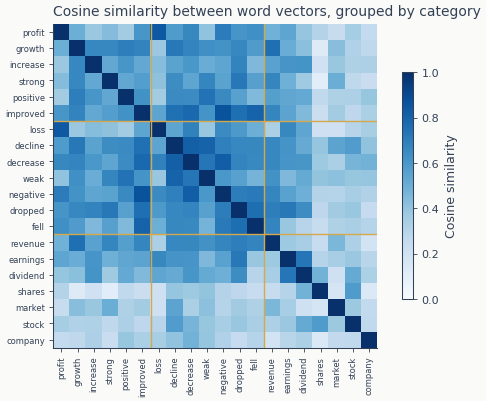

In [14]:
fig, ax = plt.subplots(figsize=FIGSIZE["single_tall"])
image = ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(selected_words)))
ax.set_yticks(range(len(selected_words)))
ax.set_xticklabels(selected_words, rotation=90, fontsize=6)
ax.set_yticklabels(selected_words, fontsize=6)

# Boundaries between the three groups, so the blocks are readable without counting words.
boundary = 0
for category in list(categories)[:-1]:
    boundary += sum(1 for g in selected_groups if g == category)
    ax.axhline(boundary - 0.5, color=COLORS["amber"], linewidth=1)
    ax.axvline(boundary - 0.5, color=COLORS["amber"], linewidth=1)

fig.colorbar(image, ax=ax, shrink=0.7, label="Cosine similarity")
ax.set_title("Cosine similarity between word vectors, grouped by category")
show_with_alt(
    fig,
    "A square matrix of cosine similarities between about twenty word vectors, shaded from "
    "white at zero to dark at one, with the words ordered into three groups marked by amber "
    "lines. Apart from the dark diagonal where each word meets itself, the shading is fairly "
    "even across the whole matrix: the blocks pairing a group with itself are no darker than "
    "the blocks pairing it with a different group, and the darkest off-diagonal cell lies in "
    "the block pairing the positive words against the negative ones.",
)

这些块没有分开，而且打印出的两个均值不依赖图像就说明了同一件事：在余弦相似度下，这些词不会按极性聚集，一个词与其同极性词的距离，并不比与其反义词的距离更近。远离对角线的两个最暗单元格都位于将两个相反词组配对的块中——`improved` 对 `negative`，以及 `profit` 对 `loss`。

主题名词的表现也是如此。它们没有形成自己的块，因为 `revenue` 由它出现的句子决定，而不是由它指代的内容决定；而那些句子也正是 `profit` 和 `growth` 出现的句子。

几何结构确实编码的是哪些词被用于相同的框架。这是一个真实且有价值的信号——正是它使最近邻查询成为扩展查询或寻找可替代词的好方法——但它不适合作为特征交给一个期望距离表示一致性的情感模型。

## 同一套机制，用于投资组合

`02_asset_embeddings` 并没有把这项技术适配到资产上；它是在不同的语料上运行同一套技术。对应关系逐项完全一致：

| 这里 | 那里 |
|---|---|
| 一个句子 | 申报机构的投资组合 |
| 句子中的一个词 | 其中持有的一只股票 |
| 共享一个句子的词被推到一起 | 被同一机构持有的股票被推到一起 |
| 最近邻给出可替代的词 | 最近邻给出可替代的股票 |

这种迁移把本 notebook 的发现一并带过去。共同持有并不等于相似表现，正如共现并不等于相似含义；而一位经理作为配对交易持有的两只股票被放在一起，恰恰是因为预期它们会走势分化。要带到下一个 notebook 的问题是：它的嵌入衡量的究竟是这两件事中的哪一件。

## 静态嵌入不编码什么

四个限制，按它们让你付出代价的顺序排列。每一个都关乎几何结构承载了什么，而不是最终能在其上构建什么。

1. **极性不是这个空间中的一个方向。** 上文已演示：距离衡量的是可互换的使用方式，因此 `profit` 和 `loss` 很近。在带标签句子上训练的有监督分类器仍然可以把它们分开——`03_sentiment_evolution` 正是在平均向量上这么做——因为两个靠得很近的向量仍然是不同的点。标签必须提供的是方向本身，这就是为什么仅按相似度排序的无监督方法会把两者混为一谈。
2. **每个词一个向量，无论它当时表示什么含义。** 公司 `Apple` 和水果 `apple` 被平均成一个点，费用 `charge` 和指控 `charge` 也是如此。仅凭向量无法说明某次出现承载的是哪个义项，因此下游模型必须读取周围词来区分它们——这正是下面的上下文化模型在构造上做到的，而不是作为一种修补。
3. **对于从未见过的词无话可说。** 上个月才上市的 ticker、语料中不存在的专业术语，以及任何拼写错误，都处于词表之外，根本没有向量，而不是一个质量很差的向量。
4. **词之上没有单位。** “Net loss narrowed”（净亏损收窄）是正面的，而它的三个词中没有一个是正面的。对这三个词取平均或求和会忽略顺序和否定，因此组合是下游模型必须学习的东西，而不是向量提供的东西。

第 10.4 节的上下文化模型改变的是被编码的内容，而不是可以在其之上学到的东西：一个词的向量变成它所在句子的函数，这解决了前三个限制；并且模型会为句子本身输出一个向量，这解决了第四个限制。

## 关键要点

1. **共现衡量主题，而不是含义。** 当两个词用于相同的框架时，该方法会把它们放在一起。把最近邻列表读作“像这样使用”，并在你把它当作特征信任之前，检查目标词的反义词。
2. **分词器是模型的一部分。** 保留数字 token 会把货币片段放到语料中最重要的词的邻居里。先决定什么是一个 token，再决定向量意味着什么。
3. **语料规模换来精度，领域数据换来覆盖范围。** 大型通用模型能区分小型模型混淆的词；小型领域模型读过大型模型没读过的句子。两者不能互相替代，而有用的问题是：你的任务能容忍哪种失败。
4. **可复现性要付出一个 worker 的代价。** 不止一个训练线程意味着更新顺序由操作系统决定，种子不再决定结果。

训练好的模型和一份简短摘要会写入本章的输出目录。没有其他 notebook 读取它们——`02_asset_embeddings` 会在投资组合上训练自己的模型，而 `03_sentiment_evolution` 会下载预训练向量——所以这部分是留给这样的读者：他们想加载这些向量并进行探查，而不必再次承担训练运行的代价。

In [15]:
chapter_dir = get_chapter_dir(10)
output_dir = chapter_dir / "output" / "word2vec"
output_dir.mkdir(parents=True, exist_ok=True)
model.save(str(output_dir / "word2vec_financial.model"))
print(f"Model saved to: {output_dir / 'word2vec_financial.model'}")

results_file = output_dir / "results.md"
algorithm = "Skip-gram" if w2v_config["sg"] else "CBOW"
with open(results_file, "w") as f:
    f.write("# Word2Vec training results\n\n")
    f.write("## Configuration\n")
    f.write(f"- Training data: Financial PhraseBank ({len(sentences):,} sentences)\n")
    f.write(f"- Vocabulary size: {len(model.wv):,}\n")
    f.write(f"- Embedding dimension: {model.wv.vector_size}\n")
    f.write(f"- Context window: {w2v_config['window']}\n")
    f.write(f"- Algorithm: {algorithm} with {w2v_config['negative']} negative samples\n\n")
    f.write("## What the vectors encode\n")
    f.write("Co-occurrence, which is topic rather than meaning. On this corpus the nearest\n")
    f.write("neighbor of `profit` is `loss`, because the two are reported in identical\n")
    f.write("sentence frames. Treat a neighbor list as evidence of interchangeable usage.\n")

print(f"Results saved to: {results_file}")

Model saved to: 10_text_feature_engineering/output/word2vec/word2vec_financial.model
Results saved to: 10_text_feature_engineering/output/word2vec/results.md
